# Lab 5 ? Motor parameter identification

**Name:** Yusufboy Komiljonov  
**Course / group:** JAR2

This notebook analyzes the recordings from my TRIK robot. It estimates each wheel's steady angular speed and motor time constant from the measured encoder step responses, compares the two wheels, and checks one measured response against the fitted model.

> **Data used:** 40 PWM step files for each of wheels 1 and 2, plus one battery-voltage file for each wheel. The notebook reads the files in the neighboring `motor_data/` folder; keep that folder beside this notebook.

## 1. Experiment and data format

For every nonzero PWM level from ?100% to +100% in 5% increments, the program records the encoder angle and the sample time for about two seconds. Each test starts from a reset encoder, and the motor rests between tests. The two battery files report approximately 11.804 V.

Each step file contains two columns: **position in degrees** and **time in milliseconds**. I convert these to radians and seconds before fitting the motor model. Wheel IDs are kept as recorded in the filenames.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display

DATA_DIR = Path("motor_data")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Put this notebook beside the motor_data folder; current folder: "
        + str(Path.cwd())
    )

expected_pwms = set(range(-100, 0, 5)) | set(range(5, 101, 5))
battery_v = {}
for wheel_id in (1, 2):
    battery_file = DATA_DIR / f"wheel_{wheel_id}_battery.txt"
    if not battery_file.exists():
        raise FileNotFoundError(f"Missing battery reading: {battery_file}")
    battery_v[wheel_id] = float(battery_file.read_text().split(":", 1)[1].strip())

step_files = {}
for wheel_id in (1, 2):
    for path in DATA_DIR.glob(f"wheel_{wheel_id}_v_*.txt"):
        match = re.fullmatch(rf"wheel_{wheel_id}_v_(-?\d+)\.txt", path.name)
        if match:
            step_files[(wheel_id, int(match.group(1)))] = path

for wheel_id in (1, 2):
    observed = {pwm for (wid, pwm) in step_files if wid == wheel_id}
    missing = sorted(expected_pwms - observed)
    extra = sorted(observed - expected_pwms)
    print(
        f"Wheel {wheel_id}: {len(observed)} step files, "
        f"battery = {battery_v[wheel_id]:.3f} V"
    )
    if missing or extra:
        print("  Missing PWM levels:", missing, "Unexpected levels:", extra)
    else:
        print("  All 40 required PWM levels are present.")

print("Total files:", len(list(DATA_DIR.iterdir())))

Wheel 1: 40 step files, battery = 11.804 V
  All 40 required PWM levels are present.
Wheel 2: 40 step files, battery = 11.804 V
  All 40 required PWM levels are present.
Total files: 82


## 2. Motor model and fitting method

I use the first-order DC motor model

$$
T_m\frac{d\omega}{dt}+\omega=\frac{U}{k_e},\qquad
\frac{d\theta}{dt}=\omega.
$$

For a constant-voltage step starting from rest, the predicted angle is

$$
\theta(t)=\omega_{ss}\left[t-T_m+T_m e^{-t/T_m}\right],
\qquad \omega_{ss}=\frac{U}{k_e}.
$$

For each file, nonlinear least squares fits `?_ss` and `T_m` directly to the measured angle trace. The actual input voltage is calculated as `U = (PWM / 100) ? battery voltage`. The fit bounds `T_m` between 0.005 and 2 seconds; a result at a bound, a very small angle change, or a large residual is flagged for caution rather than treated as a reliable parameter.

In [2]:
def angle_model(time_s, omega_ss, tau_s):
    return omega_ss * (time_s - tau_s + tau_s * np.exp(-time_s / tau_s))


def fit_step(path):
    raw = np.loadtxt(path, comments="#", ndmin=2)
    if raw.shape[1] != 2 or len(raw) < 4:
        raise ValueError(f"Expected position/time columns in {path}")

    position_deg = raw[:, 0]
    time_s = (raw[:, 1] - raw[0, 1]) / 1000.0
    angle_rad = np.deg2rad(position_deg - position_deg[0])
    if time_s[-1] <= 0 or np.any(np.diff(time_s) < 0):
        raise ValueError(f"Invalid sample timestamps in {path}")

    tail = int(0.6 * len(time_s))
    initial_speed = np.polyfit(time_s[tail:], angle_rad[tail:], 1)[0]
    if abs(initial_speed) < 0.01:
        initial_speed = angle_rad[-1] / time_s[-1]

    params, _ = curve_fit(
        angle_model,
        time_s,
        angle_rad,
        p0=[initial_speed, 0.15],
        bounds=([-np.inf, 0.005], [np.inf, 2.0]),
        maxfev=30000,
    )
    predicted = angle_model(time_s, *params)
    rmse = float(np.sqrt(np.mean((predicted - angle_rad) ** 2)))
    travel_deg = float(np.rad2deg(np.ptp(angle_rad)))
    omega_ss, tau_s = map(float, params)
    low_confidence = (
        tau_s <= 0.0051 or tau_s >= 1.95 or travel_deg < 30 or rmse > 0.1
    )
    return {
        "time_s": time_s,
        "angle_rad": angle_rad,
        "omega_ss_rad_s": omega_ss,
        "T_m_s": tau_s,
        "rmse_rad": rmse,
        "travel_deg": travel_deg,
        "quality": "low confidence" if low_confidence else "fit",
    }


records = []
responses = {}
for (wheel_id, pwm), path in sorted(step_files.items()):
    result = fit_step(path)
    responses[(wheel_id, pwm)] = result
    records.append({
        "Wheel": wheel_id,
        "PWM (%)": pwm,
        "U (V)": pwm / 100 * battery_v[wheel_id],
        "?_ss (rad/s)": result["omega_ss_rad_s"],
        "T_m (s)": result["T_m_s"],
        "RMSE (rad)": result["rmse_rad"],
        "Angle travel (deg)": result["travel_deg"],
        "Fit quality": result["quality"],
    })

results = pd.DataFrame(records).sort_values(["Wheel", "PWM (%)"]).reset_index(drop=True)
print(f"Fitted {len(results)} step responses.")
print(f"Low-confidence fits: {(results['Fit quality'] == 'low confidence').sum()}.")
display(results.head())

Fitted 80 step responses.
Low-confidence fits: 12.


,Wheel,PWM (%),U (V),?_ss (rad/s),T_m (s),RMSE (rad),Angle travel (deg),Fit quality
0,1,-100,-11.804438,-14.795815,0.081222,0.026202,1624.0,fit
1,1,-95,-11.214216,-14.191813,0.097014,0.024936,1544.0,fit
2,1,-90,-10.623994,-13.170481,0.120259,0.032053,1417.0,fit
3,1,-85,-10.033772,-12.299583,0.162584,0.023286,1293.0,fit
4,1,-80,-9.443550,-11.917602,0.188371,0.018812,1235.0,fit


## 3. Fitted parameters at every PWM level

The tables below show the measured voltage, fitted steady speed, and fitted time constant for every test. `?_ss` is signed, so a negative value means the wheel turned in the reverse direction. I keep the fit-quality flag visible for low-motion or poorly described traces.

In [3]:
for wheel_id in (1, 2):
    print(f"Wheel {wheel_id}")
    display(
        results.loc[results["Wheel"] == wheel_id, [
            "PWM (%)", "U (V)", "?_ss (rad/s)", "T_m (s)",
            "RMSE (rad)", "Fit quality",
        ]].round(4).reset_index(drop=True)
    )

Wheel 1


,PWM (%),U (V),?_ss (rad/s),T_m (s),RMSE (rad),Fit quality
0,-100,-11.8044,-14.7958,0.0812,0.0262,fit
1,-95,-11.2142,-14.1918,0.0970,0.0249,fit
2,-90,-10.6240,-13.1705,0.1203,0.0321,fit
3,-85,-10.0338,-12.2996,0.1626,0.0233,fit
4,-80,-9.4436,-11.9176,0.1884,0.0188,fit
5,-75,-8.8533,-11.3167,0.2185,0.0273,fit
6,-70,-8.2631,-10.2703,0.2314,0.0360,fit
7,-65,-7.6729,-9.2236,0.3387,0.0132,fit
8,-60,-7.0827,-9.2354,0.3742,0.0216,fit
9,-55,-6.4924,-7.7712,0.3001,0.0261,fit


Wheel 2


,PWM (%),U (V),?_ss (rad/s),T_m (s),RMSE (rad),Fit quality
0,-100,-11.8044,-14.1386,0.0679,0.0266,fit
1,-95,-11.2142,-13.4776,0.0775,0.0419,fit
2,-90,-10.6240,-12.3237,0.1293,0.0412,fit
3,-85,-10.0338,-11.3855,0.1474,0.0155,fit
4,-80,-9.4436,-11.0680,0.1582,0.0297,fit
5,-75,-8.8533,-10.3569,0.1892,0.0949,fit
6,-70,-8.2631,-5.8397,0.2272,0.0164,fit
7,-65,-7.6729,-4.3746,0.3038,0.0171,fit
8,-60,-7.0827,-4.5962,0.1494,0.0817,fit
9,-55,-6.4924,-3.7599,0.2935,0.0164,fit


## 4. Steady speed versus actual voltage

At medium and high PWM, the model predicts that speed changes approximately linearly with voltage. I fit a straight line separately for each wheel using the tests at `|PWM| ? 25%`; excluding the smallest PWM values keeps the dead-zone region from dominating the motor-gain estimate. The slope is `1/k_e`, so `k_e` is its reciprocal. Shading marks the tested low-speed region around zero; the threshold is only approximate because PWM was tested in 5% steps.

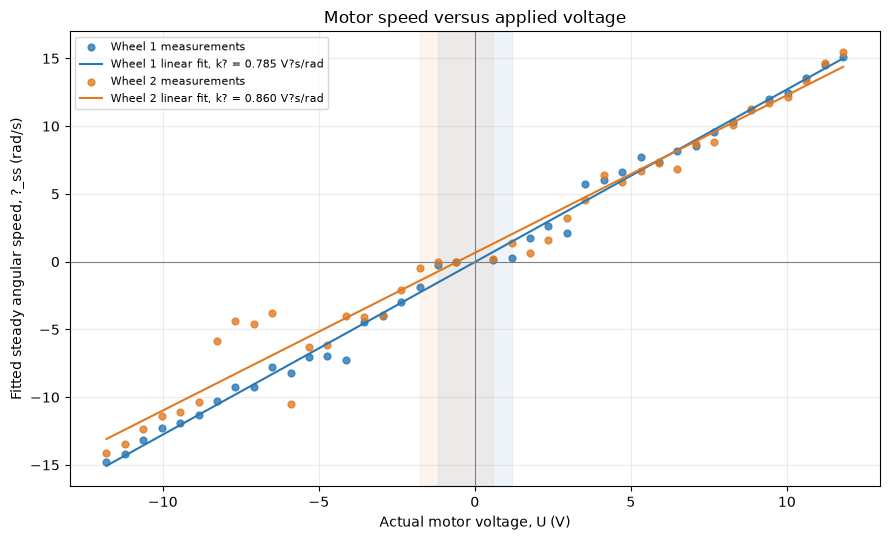

,Wheel,k_e (V?s/rad),Speed gain (rad/s/V),Dead-zone estimate (? / +)
0,1,0.7853,1.2734,10% / 10%
1,2,0.8597,1.1632,15% / 5%


In [4]:
def estimate_dead_zone(wheel_id, direction):
    data = results[(results["Wheel"] == wheel_id) & (np.sign(results["PWM (%)"]) == direction)]
    near_zero = data[np.abs(data["?_ss (rad/s)"]) <= 0.5]
    if near_zero.empty:
        return int(data["PWM (%)"].abs().min()), True
    return int(near_zero["PWM (%)"].abs().max()), False


motor_fits = {}
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#2878B5", "#E07A22"]
for color, wheel_id in zip(colors, (1, 2)):
    data = results[results["Wheel"] == wheel_id]
    linear = data[data["PWM (%)"].abs() >= 25]
    slope, intercept = np.polyfit(linear["U (V)"], linear["?_ss (rad/s)"], 1)
    if slope <= 0:
        raise ValueError(f"Wheel {wheel_id}: fitted speed/voltage slope is not positive")
    negative, neg_is_upper_bound = estimate_dead_zone(wheel_id, -1)
    positive, pos_is_upper_bound = estimate_dead_zone(wheel_id, 1)
    motor_fits[wheel_id] = {
        "slope_rad_s_per_v": float(slope),
        "intercept_rad_s": float(intercept),
        "k_e_v_s_per_rad": float(1 / slope),
        "negative_dead_zone_pwm": negative,
        "positive_dead_zone_pwm": positive,
        "negative_is_upper_bound": neg_is_upper_bound,
        "positive_is_upper_bound": pos_is_upper_bound,
    }
    ax.scatter(data["U (V)"], data["?_ss (rad/s)"], color=color, s=24, alpha=0.8,
               label=f"Wheel {wheel_id} measurements")
    u_line = np.linspace(data["U (V)"].min(), data["U (V)"].max(), 150)
    ax.plot(u_line, slope * u_line + intercept, color=color,
            label=f"Wheel {wheel_id} linear fit, k? = {1/slope:.3f} V?s/rad")
    left_bound = -negative * battery_v[wheel_id] / 100
    right_bound = positive * battery_v[wheel_id] / 100
    ax.axvspan(left_bound, right_bound, color=color, alpha=0.08)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Actual motor voltage, U (V)")
ax.set_ylabel("Fitted steady angular speed, ?_ss (rad/s)")
ax.set_title("Motor speed versus applied voltage")
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

summary = []
for wheel_id in (1, 2):
    fit = motor_fits[wheel_id]
    neg = ("?" if fit["negative_is_upper_bound"] else "") + str(fit["negative_dead_zone_pwm"]) + "%"
    pos = ("?" if fit["positive_is_upper_bound"] else "") + str(fit["positive_dead_zone_pwm"]) + "%"
    summary.append({
        "Wheel": wheel_id,
        "k_e (V?s/rad)": fit["k_e_v_s_per_rad"],
        "Speed gain (rad/s/V)": fit["slope_rad_s_per_v"],
        "Dead-zone estimate (? / +)": f"{neg} / {pos}",
    })
display(pd.DataFrame(summary).round(4))

The fitted `k_e` values are not identical because the two motors do not have exactly the same speed response. The dead-zone estimates are rough: a value such as `?5%` means the motor already exceeded the low-speed threshold at the smallest tested magnitude, so the experiment only tells us that the true threshold is at or below that level.

## 5. How the fitted time constant changes

For an ideal first-order motor at fixed load, `T_m` should be approximately a motor property. Here I plot the fitted value at every voltage to see whether the measured step responses support that simplification. A fit at the lower or upper bound is marked low confidence; short or noisy traces can make the fitted time constant unreliable.

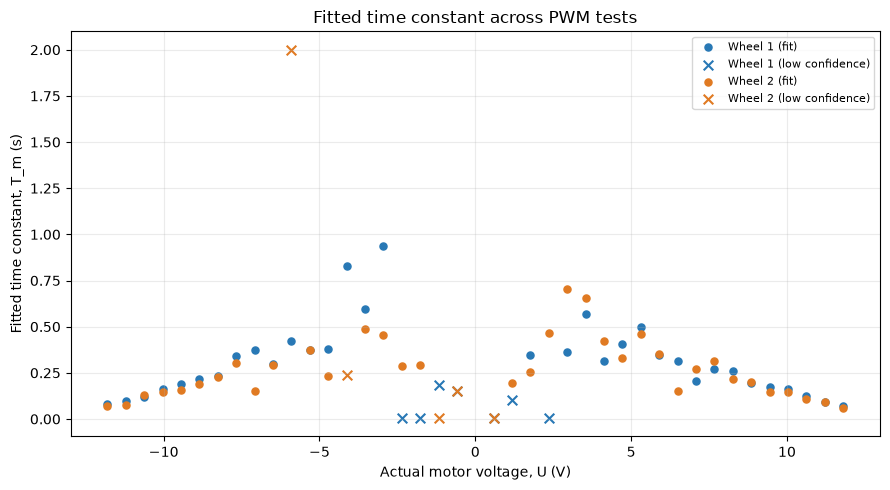

,min,median,max
Wheel,,,
1,0.005,0.225,0.937
2,0.005,0.230,2.000


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for color, wheel_id in zip(colors, (1, 2)):
    data = results[results["Wheel"] == wheel_id]
    good = data[data["Fit quality"] == "fit"]
    caution = data[data["Fit quality"] == "low confidence"]
    ax.scatter(good["U (V)"], good["T_m (s)"], color=color, s=26,
               label=f"Wheel {wheel_id} (fit)")
    ax.scatter(caution["U (V)"], caution["T_m (s)"], color=color, marker="x", s=48,
               label=f"Wheel {wheel_id} (low confidence)")
ax.set_xlabel("Actual motor voltage, U (V)")
ax.set_ylabel("Fitted time constant, T_m (s)")
ax.set_title("Fitted time constant across PWM tests")
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

tau_summary = results.groupby("Wheel")["T_m (s)"].agg(["min", "median", "max"]).round(3)
display(tau_summary)

## 6. One measured step and its fitted model

The plot below uses the +50% test on wheel 1. The solid curve is the encoder measurement; the dashed curve is the model evaluated with the `?_ss` and `T_m` fitted from that same step. Comparing the curves makes the first-order approximation and any mismatch visible.

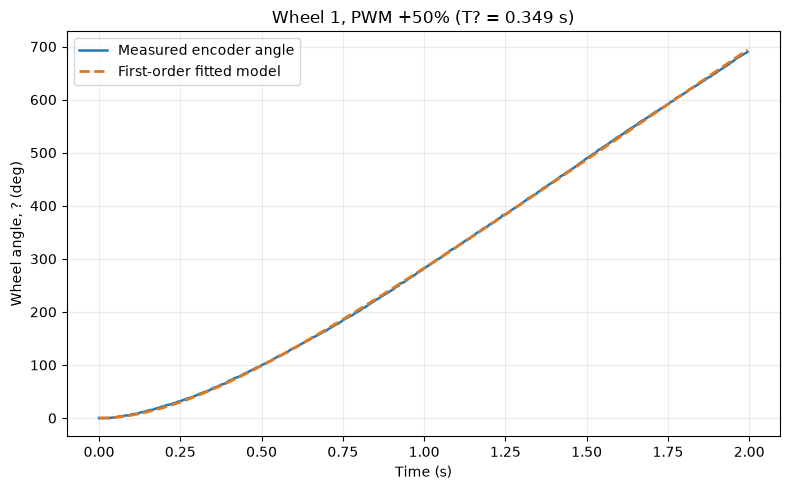

?_ss = 7.355 rad/s; T_m = 0.349 s; fit RMSE = 0.029 rad.


In [6]:
example_wheel, example_pwm = 1, 50
example = responses[(example_wheel, example_pwm)]
t = example["time_s"]
measured_deg = np.rad2deg(example["angle_rad"])
simulated_deg = np.rad2deg(
    angle_model(t, example["omega_ss_rad_s"], example["T_m_s"])
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t, measured_deg, color="#2878B5", linewidth=1.8, label="Measured encoder angle")
ax.plot(t, simulated_deg, color="#E07A22", linestyle="--", linewidth=2,
        label="First-order fitted model")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Wheel angle, ? (deg)")
ax.set_title(
    f"Wheel {example_wheel}, PWM +{example_pwm}% "
    f"(T? = {example['T_m_s']:.3f} s)"
)
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
print(f"?_ss = {example['omega_ss_rad_s']:.3f} rad/s; "
      f"T_m = {example['T_m_s']:.3f} s; "
      f"fit RMSE = {example['rmse_rad']:.3f} rad.")

## 7. Conclusion

The linear speed-versus-voltage model is least reliable around zero PWM, where friction and the dead zone matter most; the measured low-speed thresholds differ by direction and wheel. Fitting the medium- and high-PWM points gives `k_e = 0.785 V?s/rad` for wheel 1 and `0.860 V?s/rad` for wheel 2, so their speed gains are measurably different. The fitted time constants also vary across the tests, and 12 of the 80 fits are flagged low confidence because movement was small, residuals were large, or the optimizer reached a bound. If both wheels receive the same command, their unequal speeds can make the robot veer, causing heading and position errors to accumulate in encoder odometry. I would use separate wheel calibrations and treat the flagged points cautiously.

## Appendix: export the full fit table

The per-PWM tables above contain every fitted step. This cell also saves a CSV copy next to the notebook, which is convenient for checking individual measurements or opening them in a spreadsheet.